# Modeling Human Activity States Using Hidden Markov Models
**Device:** Huawei P20 (EML-L09), Android 9 · **App:** Sensor Logger 1.68
**Sensors:** Accelerometer (linear acceleration), Gyroscope, Gravity · **Sampling rate:** configured 100 Hz, measured ≈98 Hz
**Activities:** standing, walking, jumping, still

## 1. Data loading and pre-processing

In [5]:
import zipfile, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_DIR, TRAIN_DIR, FIG_DIR = Path("data/raw"), Path("data/train"), Path("figures")
FS = 100                 # target sampling rate (Hz) after resampling
TRIM_START_S = 2.0       # drop the first 2 s: tapping Start, getting into the activity, sensor filters settling
TRIM_END_S = 1.0         # drop the last 1 s: reaching for the Stop button
MIN_DURATION_S = 11.0    # raw clips shorter than this get flagged
MAX_CLIP_S = 10.0        # keep only the central 10 s of each clip
ACTIVITIES = ["standing", "walking", "jumping", "still"]
SENSORS = {"Accelerometer": "acc", "Gyroscope": "gyro", "Gravity": "grav"}
NAME_RE = re.compile(r"^(standing|walking|jumping|still|test)_(\d{2})", re.IGNORECASE)

In [2]:
rows = []
for zp in sorted(RAW_DIR.glob("*.zip")):
    m = NAME_RE.match(zp.name)
    info = {"file": zp.name,
            "activity": m.group(1).lower() if m else "NAME?",
            "clip": m.group(2) if m else "--"}
    with zipfile.ZipFile(zp) as z:
        missing = [s for s in SENSORS if f"{s}.csv" not in z.namelist()]
        info["missing_sensors"] = ", ".join(missing) or "-"
        if not missing:
            t = pd.read_csv(z.open("Accelerometer.csv"))["time"].to_numpy() / 1e9
            info["duration_s"] = round(t[-1] - t[0], 2)
            info["rate_hz"] = round((len(t) - 1) / (t[-1] - t[0]), 1)
            info["max_gap_ms"] = round(np.diff(t).max() * 1000, 1)
    rows.append(info)

inventory = pd.DataFrame(rows)
problems = inventory[(inventory["activity"] == "NAME?")
                     | (inventory["missing_sensors"] != "-")
                     | (inventory["duration_s"] < MIN_DURATION_S)]
print("Files per activity:\n", inventory.groupby("activity").size(), "\n")
print("Mean measured sampling rate: %.1f Hz" % inventory["rate_hz"].mean())
print("Problem files:", len(problems))
display(problems if len(problems) else inventory.head())

Files per activity:
 activity
jumping     13
standing    13
still       13
walking     13
dtype: int64 

Mean measured sampling rate: 98.0 Hz
Problem files: 0


,file,activity,clip,missing_sensors,duration_s,rate_hz,max_gap_ms
0,jumping_01.zip,jumping,01,-,15.10,98.0,18.7
1,jumping_02.zip,jumping,02,-,14.79,98.0,18.7
2,jumping_03.zip,jumping,03,-,15.10,98.0,18.7
3,jumping_04.zip,jumping,04,-,14.49,98.1,18.7
4,jumping_05.zip,jumping,05,-,15.47,98.0,18.7


In [7]:
def load_recording(zip_path):
    """Read Accelerometer, Gyroscope and Gravity from one Sensor Logger zip, trim the edges,
    and resample all three onto one shared, evenly spaced 100 Hz time grid."""
    with zipfile.ZipFile(zip_path) as z:
        streams = {short: pd.read_csv(z.open(f"{name}.csv")).sort_values("time").drop_duplicates("time")
                   for name, short in SENSORS.items()}
    start = max(df["time"].iloc[0] for df in streams.values()) / 1e9 + TRIM_START_S
    end = min(df["time"].iloc[-1] for df in streams.values()) / 1e9 - TRIM_END_S
    if end - start > MAX_CLIP_S:                      # keep the central 10 s
        mid = (start + end) / 2
        start, end = mid - MAX_CLIP_S / 2, mid + MAX_CLIP_S / 2
    grid = start + np.arange(int(round((end - start) * FS))) / FS    
    out = pd.DataFrame({"timestamp_ns": (grid * 1e9).astype("int64"),
                        "seconds": np.round(grid - grid[0], 2)})
    for short, df in streams.items():
        t = df["time"].to_numpy() / 1e9
        for axis in "xyz":
            out[f"{short}_{axis}"] = np.interp(grid, t, df[axis].to_numpy())
    return out

TRAIN_DIR.mkdir(parents=True, exist_ok=True)
summary = []
for zp in sorted(RAW_DIR.glob("*.zip")):
    m = NAME_RE.match(zp.name)
    if not m or m.group(1).lower() == "test":
        continue
    activity, clip = m.group(1).lower(), m.group(2)
    df = load_recording(zp)
    df["activity"] = activity
    df.to_csv(TRAIN_DIR / f"{activity}_{clip}.csv", index=False)
    summary.append({"activity": activity, "clip": clip, "seconds": round(len(df) / FS, 2)})

summary = pd.DataFrame(summary)
summary.groupby("activity").agg(files=("clip", "count"), total_seconds=("seconds", "sum"))

,files,total_seconds
activity,,
jumping,13,130.0
standing,13,130.0
still,13,130.0
walking,13,130.0


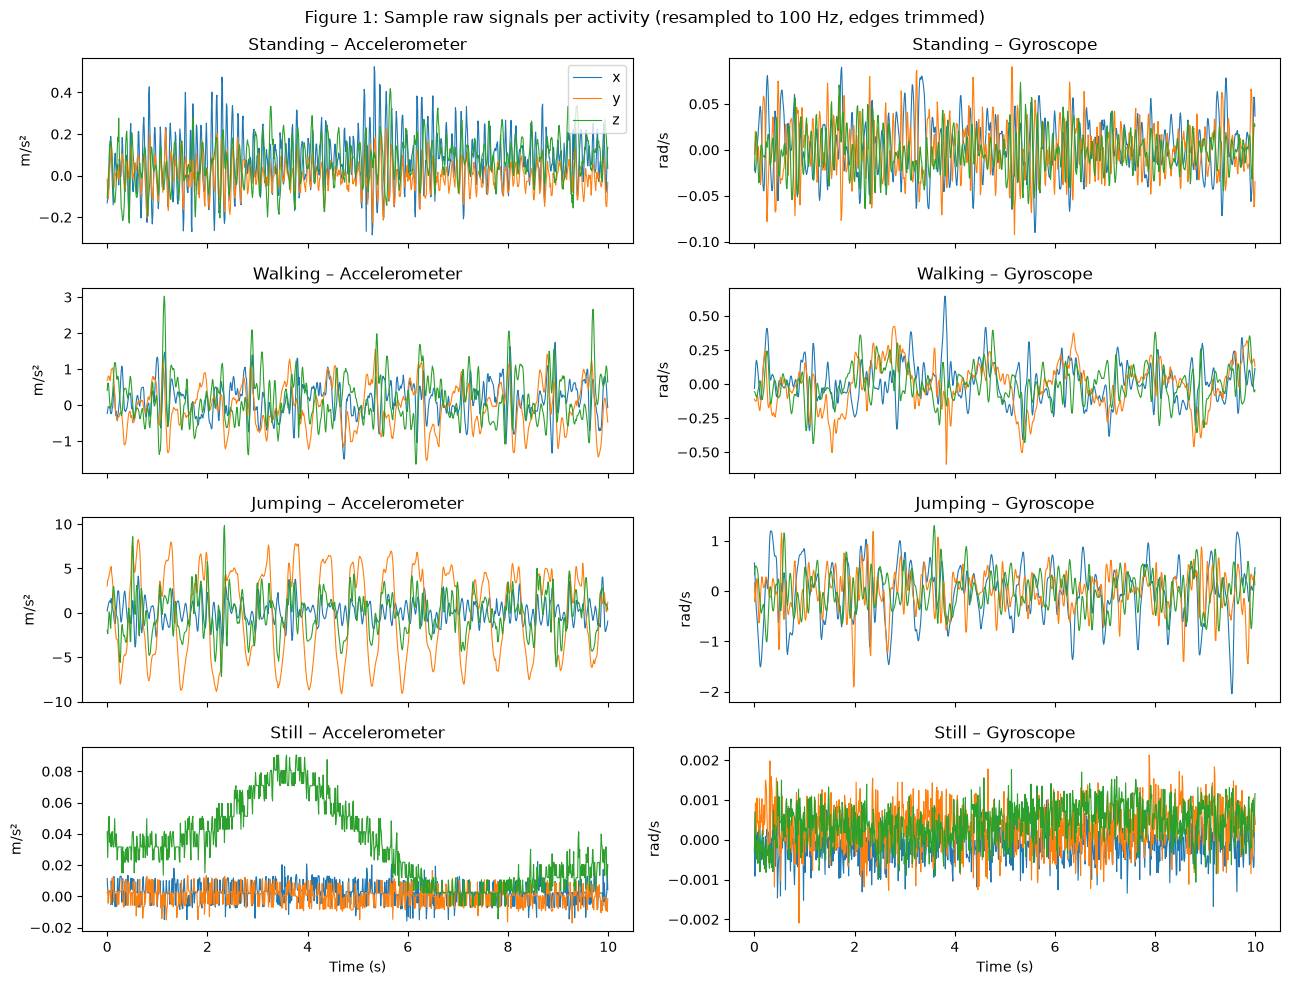

In [8]:
FIG_DIR.mkdir(exist_ok=True)
fig, axes = plt.subplots(len(ACTIVITIES), 2, figsize=(13, 10), sharex=True)
for i, activity in enumerate(ACTIVITIES):
    df = pd.read_csv(sorted(TRAIN_DIR.glob(f"{activity}_*.csv"))[0])
    for j, (sensor, unit) in enumerate([("acc", "m/s²"), ("gyro", "rad/s")]):
        ax = axes[i, j]
        for axis in "xyz":
            ax.plot(df["seconds"], df[f"{sensor}_{axis}"], lw=0.8, label=axis)
        ax.set_title(f"{activity.capitalize()} – {'Accelerometer' if sensor == 'acc' else 'Gyroscope'}")
        ax.set_ylabel(unit)
        if i == 0 and j == 0:
            ax.legend(loc="upper right")
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
fig.suptitle("Figure 1: Sample raw signals per activity (resampled to 100 Hz, edges trimmed)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_raw_signals.png", dpi=150)
plt.show()

## 2. Windowing and feature extraction
Each clip is cut into **2 s windows (200 samples at 100 Hz) with 50% overlap (1 s step)**.
- 2 s covers at least two full cycles of the slowest periodic activity (walking steps ≈ 1–2 Hz), so periodic patterns are visible inside each window.
- At 100 Hz a 2 s window gives an FFT frequency resolution of 0.5 Hz (refined to ≈0.2 Hz with zero-padding), enough to separate walking from jumping rhythms.
- 50% overlap doubles the number of observations and gives a smooth sequence (one observation per second) for the HMM.

In [9]:
WINDOW_S, STEP_S = 2.0, 1.0
WIN, STEP = int(WINDOW_S * FS), int(STEP_S * FS)
N_FFT = 512                      # zero-padded FFT length for finer frequency resolution
MOVE_BAND = (0.5, 5.0)           # frequency band of human movement (Hz)

def spectrum(signal):
    """Power spectrum of a mean-removed, Hann-windowed signal."""
    x = (signal - signal.mean()) * np.hanning(len(signal))
    power = np.abs(np.fft.rfft(x, n=N_FFT)) ** 2
    freqs = np.fft.rfftfreq(N_FFT, 1 / FS)
    return freqs, power

def window_features(w):
    """Compute the 12 features for one 2 s window."""
    acc = w[["acc_x", "acc_y", "acc_z"]].to_numpy()
    gyro = w[["gyro_x", "gyro_y", "gyro_z"]].to_numpy()
    acc_mag, gyro_mag = np.linalg.norm(acc, axis=1), np.linalg.norm(gyro, axis=1)

    feats = {
        # --- time domain ---
        "acc_mag_mean":  acc_mag.mean(),                    # overall movement intensity
        "acc_mag_std":   acc_mag.std(),                     # how much the intensity varies
        "acc_sma":       np.abs(acc).sum(axis=1).mean(),    # signal magnitude area
        "gyro_mag_mean": gyro_mag.mean(),                   # how much the phone rotates
        "gyro_mag_std":  gyro_mag.std(),
        "acc_corr_yz":   np.corrcoef(acc[:, 1], acc[:, 2])[0, 1],  # coordination between axes
        "grav_y_mean":   w["grav_y"].mean(),                # phone orientation: upright...
        "grav_z_mean":   w["grav_z"].mean(),                # ...or lying flat
    }
    # --- frequency domain (FFT) ---
    f, p = spectrum(acc_mag)
    valid = f > 0.3                                         # ignore the near-DC bins
    band = (f >= MOVE_BAND[0]) & (f <= MOVE_BAND[1])
    p_norm = p[valid] / p[valid].sum()
    feats["acc_dom_freq"] = f[valid][p[valid].argmax()]                   # rhythm of the movement
    feats["acc_band_ratio"] = p[band].sum() / p[valid].sum()              # share of energy in the movement band
    feats["acc_spec_entropy"] = -(p_norm * np.log2(p_norm + 1e-12)).sum() / np.log2(len(p_norm))  # periodic (low) vs noise (high)
    fg, pg = spectrum(gyro_mag)
    feats["gyro_dom_freq"] = fg[fg > 0.3][pg[fg > 0.3].argmax()]
    return feats

def extract_features(df):
    """Slide a window over one clip and return one row of features per window."""
    rows = []
    for i, s in enumerate(range(0, len(df) - WIN + 1, STEP)):
        feats = window_features(df.iloc[s:s + WIN])
        feats.update(window=i, t_start_s=df["seconds"].iloc[s])
        rows.append(feats)
    return pd.DataFrame(rows)

In [10]:
parts = []
for path in sorted(TRAIN_DIR.glob("*.csv")):
    df = pd.read_csv(path)
    F = extract_features(df)
    F.insert(0, "clip", path.stem)
    F["activity"] = df["activity"].iloc[0]
    parts.append(F)
train_feat = pd.concat(parts, ignore_index=True)

FEATURES = [c for c in train_feat.columns if c not in ("clip", "window", "t_start_s", "activity")]
print("Windows per activity:\n", train_feat.groupby("activity").size())
print("\nNumber of features:", len(FEATURES))
train_feat.groupby("activity")[FEATURES].mean().round(3).T

Windows per activity:
 activity
jumping     117
standing    117
still       117
walking     117
dtype: int64

Number of features: 12


activity,jumping,standing,still,walking
acc_mag_mean,5.691,0.167,0.020,0.958
acc_mag_std,2.557,0.077,0.007,0.486
acc_sma,8.171,0.247,0.028,1.425
gyro_mag_mean,0.827,0.038,0.001,0.286
gyro_mag_std,0.392,0.021,0.000,0.137
acc_corr_yz,0.744,0.307,-0.006,0.223
grav_y_mean,9.273,9.451,-0.140,9.368
grav_z_mean,2.977,2.488,9.804,2.809
acc_dom_freq,3.551,7.774,11.086,1.426
acc_band_ratio,0.659,0.221,0.142,0.615


### Normalization
Intensity features (acceleration and rotation magnitudes) span about three orders of magnitude, from ≈0.01 (still) to ≈5 (jumping). They are first **log10-transformed**, which spreads the low-motion classes apart and makes each class's distribution closer to Gaussian, matching the HMM's Gaussian emission assumption.
All features are then **Z-score normalized** (mean 0, standard deviation 1), so no single feature dominates the emission likelihood just because of its units. The mean and standard deviation are computed on the **training data only** and reused for the test data, so no information leaks from the unseen set.

In [11]:
LOG_FEATURES = ["acc_mag_mean", "acc_mag_std", "acc_sma", "gyro_mag_mean", "gyro_mag_std"]

def transform(F):
    X = F[FEATURES].copy()
    for c in LOG_FEATURES:
        X[c] = np.log10(X[c] + 1e-4)       # small offset avoids log(0) for perfectly still windows
    return X

X_train_raw = transform(train_feat)
feat_mean, feat_std = X_train_raw.mean(), X_train_raw.std()   # fitted on TRAINING data only
X_train = (X_train_raw - feat_mean) / feat_std

X_train.describe().loc[["mean", "std"]].round(2)

,acc_mag_mean,acc_mag_std,acc_sma,gyro_mag_mean,gyro_mag_std,acc_corr_yz,grav_y_mean,grav_z_mean,acc_dom_freq,acc_band_ratio,acc_spec_entropy,gyro_dom_freq
mean,0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


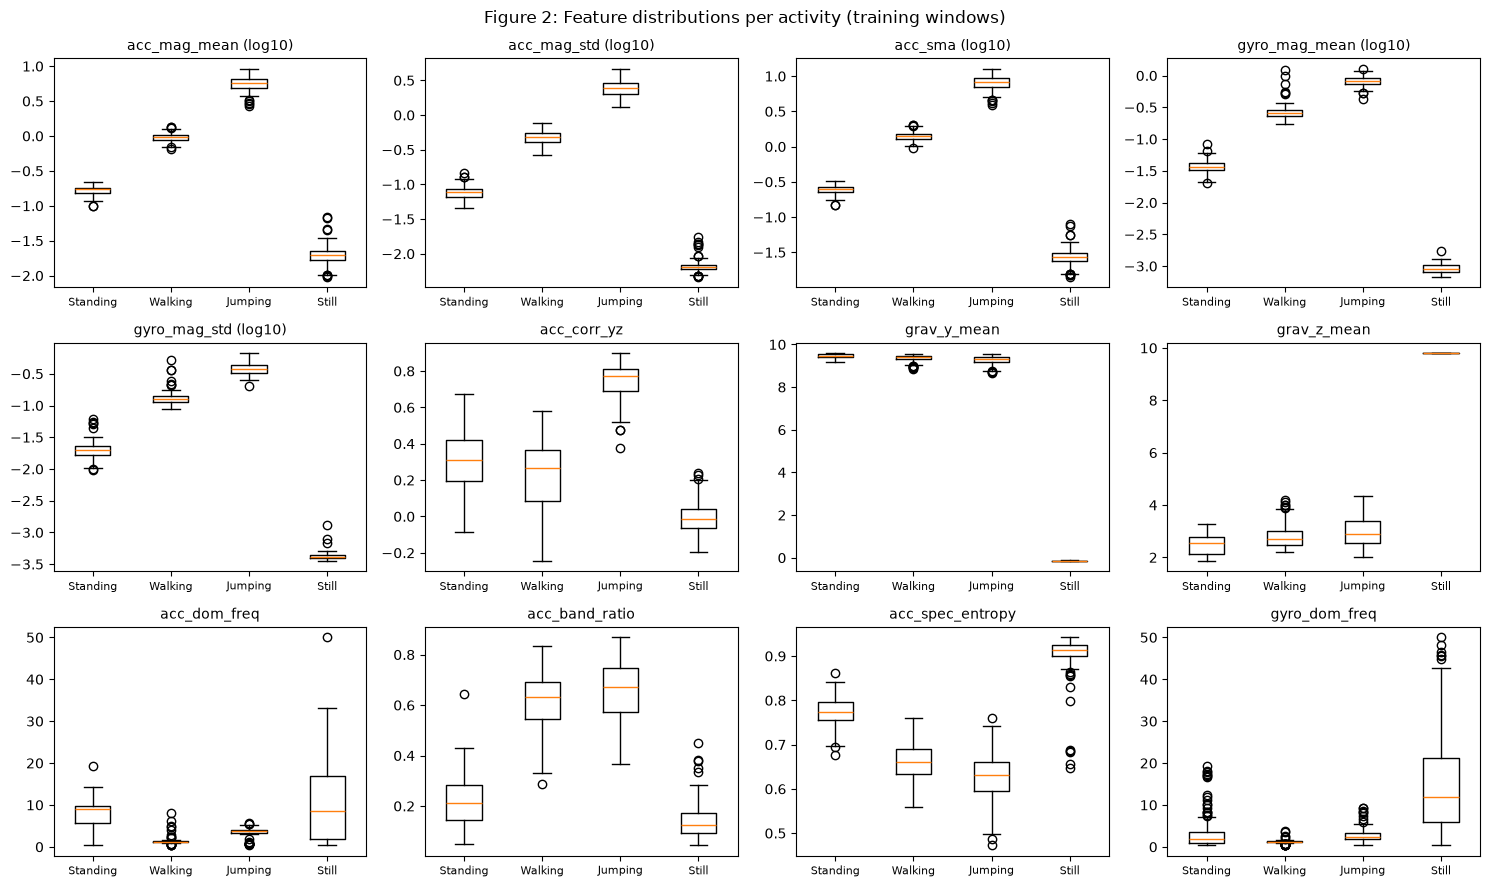

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, c in zip(axes.flat, FEATURES):
    ax.boxplot([X_train_raw.loc[train_feat["activity"] == a, c] for a in ACTIVITIES],
               tick_labels=[a.capitalize() for a in ACTIVITIES])
    ax.set_title(c + (" (log10)" if c in LOG_FEATURES else ""), fontsize=10)
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Figure 2: Feature distributions per activity (training windows)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_feature_boxplots.png", dpi=150)
plt.show()

## 3. HMM model components

| Element | In this project |
|---|---|
| Hidden states (Z) | 4 activities: standing, walking, jumping, still |
| Observations (X) | 12-dimensional normalized feature vector per 2 s window (one per second) |
| Transition probabilities (A) | 4×4 matrix, P(activity at t+1 \| activity at t) |
| Emission probabilities (B) | One Gaussian per state over the 12 features (diagonal covariance) |
| Initial probabilities (π) | P(first window's activity) |

### Algorithm choice
- **Baum-Welch (EM)** trains the model. It estimates π, A and the Gaussian emission parameters by maximizing the likelihood of the training sequences. It is initialized from the labelled windows, so each hidden state stays tied to a known activity and the decoded states can be scored against true labels.
- **Forward-backward** computes the posterior state probabilities Baum-Welch needs, and the forward pass gives the sequence log-likelihood used as the **convergence criterion** (stop when the improvement < 1e-4).
- **Viterbi** finds the single most likely activity sequence for a recording. Its output is the predicted label for every window, so it directly produces the **confusion matrix, sensitivity, specificity and accuracy** used in the evaluation.

### Design decisions
- **Log-space computation:** multiplying hundreds of small probabilities underflows to zero, so all recursions use log-probabilities and a stable log-sum-exp.
- **Diagonal covariance:** with 12 features and 117 windows per activity, a full covariance needs 78 parameters per state, and the intensity features are strongly correlated, which makes full covariances nearly singular. Diagonal Gaussians are more stable with this amount of data.
- **Variance floor (0.01):** some features barely vary within a class (e.g. gravity direction when the phone lies still). Without a floor the Gaussian collapses and any tiny difference on a new day, such as a slightly tilted table, would give near-zero likelihood.
- **Probability floor (1e-6) on π and A:** no transition is treated as strictly impossible, so the model can still follow an activity change it never saw in training.

In [13]:
def logsumexp(a, axis=None, keepdims=False):
    """Numerically stable log(sum(exp(a)))."""
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    out = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return out if keepdims else np.squeeze(out, axis=axis)

In [14]:
class GaussianHMM:
    """Hidden Markov Model with diagonal-covariance Gaussian emissions, written from scratch in NumPy.
    All probabilities are handled in log-space to avoid numerical underflow on long sequences."""

    def __init__(self, n_states, var_floor=1e-2, prob_floor=1e-6, tol=1e-4, max_iter=200):
        self.K = n_states
        self.var_floor = var_floor      # minimum variance per feature (prevents collapsing Gaussians)
        self.prob_floor = prob_floor    # minimum probability for pi and A (no transition is ever 'impossible')
        self.tol = tol                  # convergence: stop when log-likelihood improves by less than this
        self.max_iter = max_iter        # safety cap only; convergence is decided by tol
        self.history = []

    # ---------- parameter helpers ----------
    def _normalize(self, p, axis=None):
        p = np.maximum(p, self.prob_floor)
        return p / p.sum(axis=axis, keepdims=True)

    def init_supervised(self, sequences, labels):
        """Initial estimate of pi, A, means and variances from labelled sequences (one label per window).
        This gives Baum-Welch a sensible starting point and fixes which hidden state means which activity."""
        X, y = np.vstack(sequences), np.concatenate(labels)
        self.means = np.array([X[y == k].mean(axis=0) for k in range(self.K)])
        self.vars = np.array([np.maximum(X[y == k].var(axis=0), self.var_floor) for k in range(self.K)])
        counts = np.zeros((self.K, self.K))
        starts = np.zeros(self.K)
        for lab in labels:
            starts[lab[0]] += 1
            for a, b in zip(lab[:-1], lab[1:]):
                counts[a, b] += 1
        self.pi = self._normalize(starts)
        self.A = self._normalize(counts, axis=1)
        return self

    # ---------- core computations ----------
    def _log_emission(self, X):
        """log N(x_t | mean_k, diag(var_k)) for every time step t and state k -> shape (T, K)."""
        diff = X[:, None, :] - self.means[None, :, :]
        return -0.5 * (np.log(2 * np.pi * self.vars).sum(axis=1)[None, :]
                       + (diff ** 2 / self.vars[None, :, :]).sum(axis=2))

    def _forward(self, logB):
        T = len(logB)
        log_alpha = np.zeros((T, self.K))
        log_alpha[0] = np.log(self.pi) + logB[0]
        logA = np.log(self.A)
        for t in range(1, T):
            log_alpha[t] = logsumexp(log_alpha[t - 1][:, None] + logA, axis=0) + logB[t]
        return log_alpha, logsumexp(log_alpha[-1])

    def _backward(self, logB):
        T = len(logB)
        log_beta = np.zeros((T, self.K))
        logA = np.log(self.A)
        for t in range(T - 2, -1, -1):
            log_beta[t] = logsumexp(logA + logB[t + 1][None, :] + log_beta[t + 1][None, :], axis=1)
        return log_beta

    def score(self, sequences):
        """Total log-likelihood of a list of sequences under the model (forward algorithm)."""
        return sum(self._forward(self._log_emission(X))[1] for X in sequences)

    # ---------- Baum-Welch (EM) ----------
    def fit(self, sequences, verbose=True):
        for it in range(self.max_iter):
            # E-step: accumulate expected counts over all sequences
            start_acc = np.zeros(self.K)
            trans_acc = np.zeros((self.K, self.K))
            gamma_sum = np.zeros(self.K)
            x_sum = np.zeros_like(self.means)
            x2_sum = np.zeros_like(self.means)
            total_ll = 0.0
            logA = np.log(self.A)
            for X in sequences:
                logB = self._log_emission(X)
                log_alpha, ll = self._forward(logB)
                log_beta = self._backward(logB)
                total_ll += ll
                gamma = np.exp(log_alpha + log_beta - ll)                       # P(z_t = k | X)
                log_xi = (log_alpha[:-1, :, None] + logA[None] +
                          (logB[1:] + log_beta[1:])[:, None, :] - ll)            # P(z_t = i, z_t+1 = j | X)
                start_acc += gamma[0]
                trans_acc += np.exp(log_xi).sum(axis=0)
                gamma_sum += gamma.sum(axis=0)
                x_sum += gamma.T @ X
                x2_sum += gamma.T @ (X ** 2)
            self.history.append(total_ll)

            # Convergence check on the log-likelihood
            if it > 0:
                gain = total_ll - self.history[-2]
                if verbose:
                    print(f"iter {it:3d}  log-likelihood {total_ll:12.4f}  gain {gain:.6f}")
                if gain < -1e-6:
                    print("warning: log-likelihood decreased")
                if abs(gain) < self.tol:
                    self.converged_, self.n_iter_ = True, it
                    if verbose:
                        print(f"Converged after {it} iterations (gain < {self.tol}).")
                    return self
            elif verbose:
                print(f"iter {it:3d}  log-likelihood {total_ll:12.4f}")

            # M-step: re-estimate parameters from expected counts
            self.pi = self._normalize(start_acc)
            self.A = self._normalize(trans_acc, axis=1)
            self.means = x_sum / gamma_sum[:, None]
            self.vars = np.maximum(x2_sum / gamma_sum[:, None] - self.means ** 2, self.var_floor)

        self.converged_, self.n_iter_ = False, self.max_iter
        print(f"warning: stopped at max_iter={self.max_iter} without converging")
        return self

    # ---------- Viterbi decoding ----------
    def viterbi(self, X):
        """Most likely hidden-state path for one sequence."""
        logB = self._log_emission(X)
        T = len(X)
        logA = np.log(self.A)
        delta = np.zeros((T, self.K))
        backptr = np.zeros((T, self.K), dtype=int)
        delta[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + logA          # scores[i, j]: come from i, go to j
            backptr[t] = scores.argmax(axis=0)
            delta[t] = scores.max(axis=0) + logB[t]
        path = np.zeros(T, dtype=int)
        path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = backptr[t + 1, path[t + 1]]
        return path, delta[-1].max()

### Sanity check on synthetic data
Before using real data, the implementation is tested on data generated from a known 3-state HMM. Training starts from deliberately corrupted labels (30% randomly wrong). A correct implementation should: (1) increase the log-likelihood at every iteration, (2) converge by the tolerance criterion, (3) recover a transition matrix close to the true one, and (4) decode the hidden states accurately with Viterbi.

In [15]:
rng = np.random.default_rng(0)
K_t, D_t = 3, 4
true_A = np.array([[0.90, 0.05, 0.05], [0.10, 0.80, 0.10], [0.05, 0.15, 0.80]])
true_means = rng.normal(0, 2, (K_t, D_t))

def sample_sequence(T):
    z = [rng.integers(K_t)]
    for _ in range(T - 1):
        z.append(rng.choice(K_t, p=true_A[z[-1]]))
    z = np.array(z)
    return true_means[z] + rng.normal(0, 1, (T, D_t)), z

syn_seqs, syn_labels = zip(*[sample_sequence(60) for _ in range(20)])
noisy_labels = [np.where(rng.random(len(l)) < 0.3, rng.integers(K_t, size=len(l)), l) for l in syn_labels]

test_model = GaussianHMM(K_t).init_supervised(syn_seqs, noisy_labels)
print("Initial A (from noisy labels):\n", test_model.A.round(2))
test_model.fit(list(syn_seqs), verbose=False)
print(f"\nConverged: {test_model.converged_} after {test_model.n_iter_} iterations")
print("Log-likelihood never decreased:", bool(np.all(np.diff(test_model.history) > -1e-6)))
print("\nLearned A:\n", test_model.A.round(2), "\nTrue A:\n", true_A)
syn_acc = np.mean(np.concatenate([test_model.viterbi(X)[0] == z for X, z in zip(syn_seqs, syn_labels)]))
print(f"\nViterbi accuracy on synthetic data: {syn_acc:.3f}")

Initial A (from noisy labels):
 [[0.63 0.21 0.16]
 [0.29 0.52 0.19]
 [0.25 0.24 0.51]]

Converged: True after 9 iterations
Log-likelihood never decreased: True

Learned A:
 [[0.89 0.04 0.07]
 [0.13 0.78 0.09]
 [0.05 0.22 0.73]] 
True A:
 [[0.9  0.05 0.05]
 [0.1  0.8  0.1 ]
 [0.05 0.15 0.8 ]]

Viterbi accuracy on synthetic data: 0.973


## 4. Training

### Building training sequences
Each recorded clip contains a single activity, so on its own it contains no transitions for the model to learn. To train the transition matrix, the clips are combined into **13 training sessions**. Each session joins one clip of every activity in a random order, giving 4 activity bouts of ≈9 s (36 windows per session). A fixed random seed makes this reproducible.

### Training procedure
1. **Supervised initialization:** π, A, and the Gaussian means and variances are first estimated from the labelled windows. This anchors each hidden state to a known activity.
2. **Baum-Welch refinement:** EM then re-estimates all parameters by maximizing the likelihood of the training sessions, stopping when the log-likelihood gain falls below 1e-4.

In [16]:
STATE_OF = {a: k for k, a in enumerate(ACTIVITIES)}
rng = np.random.default_rng(42)

# shuffle the clips of each activity, then deal one clip of each activity into every session
clips_by_activity = {a: rng.permutation(sorted(train_feat.loc[train_feat["activity"] == a, "clip"].unique()))
                     for a in ACTIVITIES}
n_sessions = min(len(c) for c in clips_by_activity.values())

train_seqs, train_labels, session_order = [], [], []
for s in range(n_sessions):
    order = list(rng.permutation(ACTIVITIES))           # random activity order within the session
    X_parts, y_parts = [], []
    for a in order:
        mask = (train_feat["clip"] == clips_by_activity[a][s]).to_numpy()
        X_parts.append(X_train.to_numpy()[mask])
        y_parts.append(np.full(mask.sum(), STATE_OF[a]))
    train_seqs.append(np.vstack(X_parts))
    train_labels.append(np.concatenate(y_parts))
    session_order.append(order)

print(f"{len(train_seqs)} training sessions, {len(train_seqs[0])} windows each")
print("Session 1 order:", " → ".join(session_order[0]))

13 training sessions, 36 windows each
Session 1 order: standing → still → walking → jumping


In [17]:
import copy

model = GaussianHMM(n_states=len(ACTIVITIES)).init_supervised(train_seqs, train_labels)
init_model = copy.deepcopy(model)          # keep a copy of the starting point for comparison
model.fit(train_seqs)

def accuracy(m, seqs, labels):
    return np.mean(np.concatenate([m.viterbi(X)[0] == y for X, y in zip(seqs, labels)]))

print(f"\nTraining accuracy before Baum-Welch: {accuracy(init_model, train_seqs, train_labels):.3f}")
print(f"Training accuracy after  Baum-Welch: {accuracy(model, train_seqs, train_labels):.3f}")

iter   0  log-likelihood    1921.3830
iter   1  log-likelihood    1921.3830  gain -0.000000
Converged after 1 iterations (gain < 0.0001).

Training accuracy before Baum-Welch: 1.000
Training accuracy after  Baum-Welch: 1.000


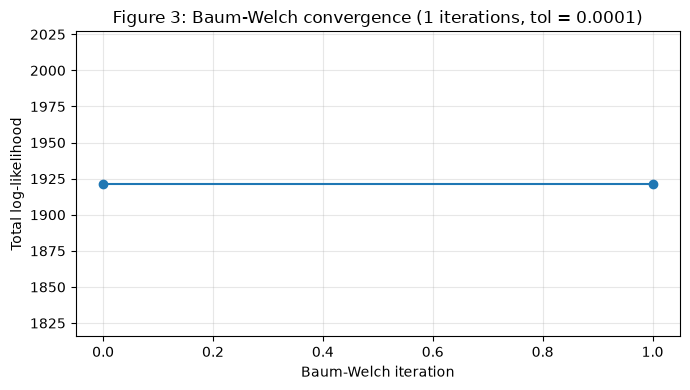

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(len(model.history)), model.history, marker="o")
ax.set_xlabel("Baum-Welch iteration")
ax.set_ylabel("Total log-likelihood")
ax.set_title(f"Figure 3: Baum-Welch convergence ({model.n_iter_} iterations, tol = {model.tol})")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_convergence.png", dpi=150)
plt.show()

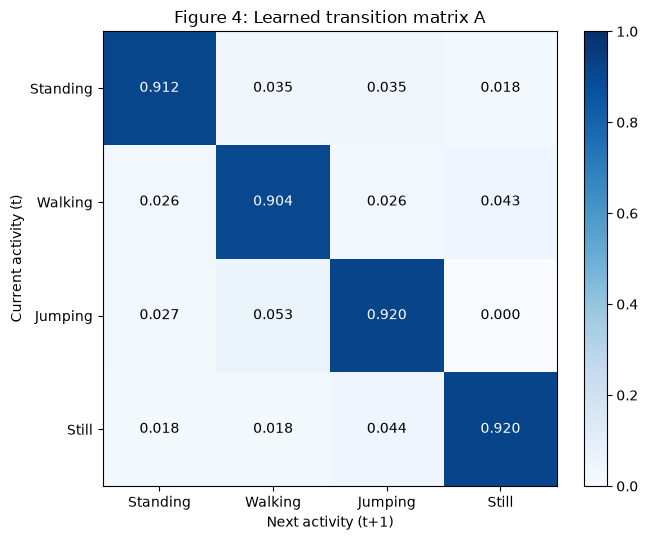

In [19]:
labels_cap = [a.capitalize() for a in ACTIVITIES]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(model.A, cmap="Blues", vmin=0, vmax=1)
for i in range(model.K):
    for j in range(model.K):
        ax.text(j, i, f"{model.A[i, j]:.3f}", ha="center", va="center",
                color="white" if model.A[i, j] > 0.5 else "black")
ax.set_xticks(range(model.K), labels_cap)
ax.set_yticks(range(model.K), labels_cap)
ax.set_xlabel("Next activity (t+1)")
ax.set_ylabel("Current activity (t)")
ax.set_title("Figure 4: Learned transition matrix A")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_transition_matrix.png", dpi=150)
plt.show()

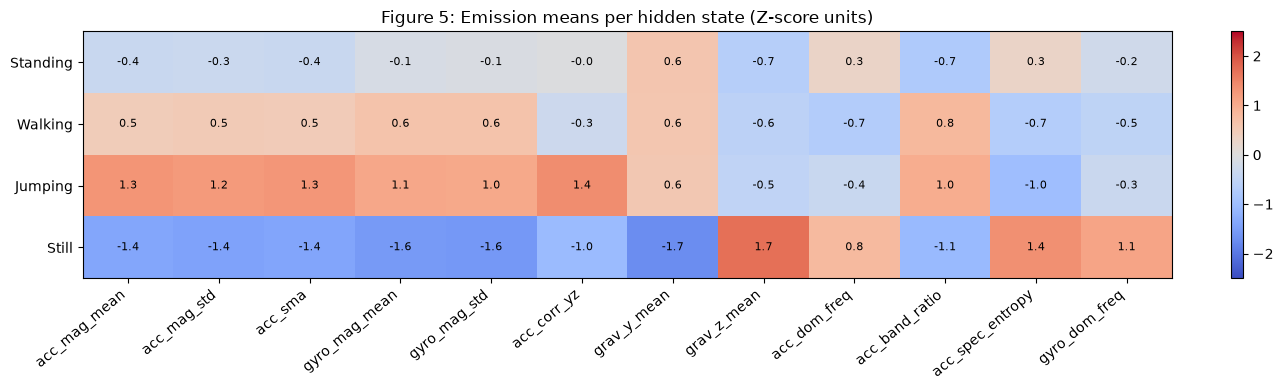

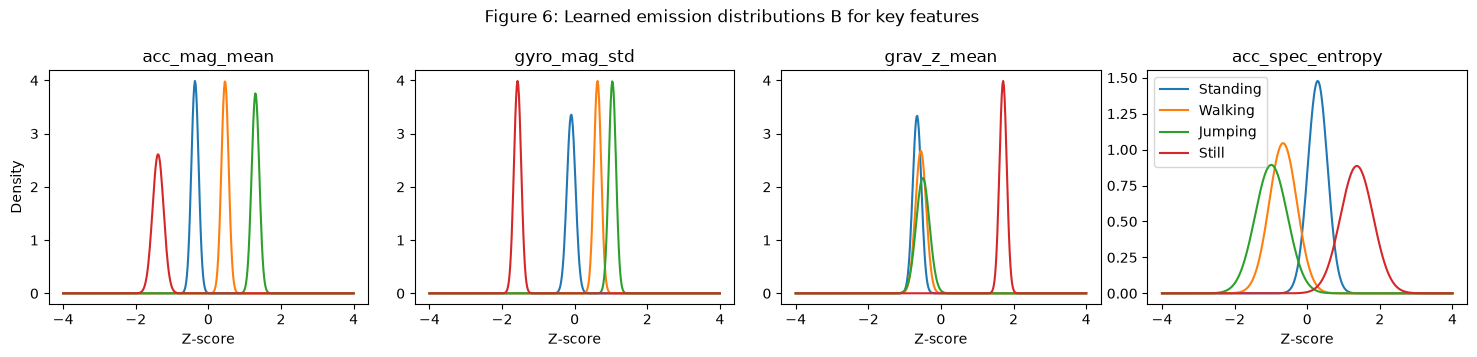

In [20]:
# Figure 5: mean of every feature for every state
fig, ax = plt.subplots(figsize=(13, 4))
im = ax.imshow(model.means, cmap="coolwarm", vmin=-2.5, vmax=2.5, aspect="auto")
for i in range(model.K):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{model.means[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=40, ha="right")
ax.set_yticks(range(model.K), labels_cap)
ax.set_title("Figure 5: Emission means per hidden state (Z-score units)")
fig.colorbar(im, ax=ax, fraction=0.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_emission_means.png", dpi=150)
plt.show()

# Figure 6: the learned Gaussian emission curves for four key features
KEY_FEATURES = ["acc_mag_mean", "gyro_mag_std", "grav_z_mean", "acc_spec_entropy"]
fig, axes = plt.subplots(1, len(KEY_FEATURES), figsize=(15, 3.6))
grid = np.linspace(-4, 4, 400)
for ax, feat_name in zip(axes, KEY_FEATURES):
    j = FEATURES.index(feat_name)
    for k, a in enumerate(labels_cap):
        m, v = model.means[k, j], model.vars[k, j]
        ax.plot(grid, np.exp(-(grid - m) ** 2 / (2 * v)) / np.sqrt(2 * np.pi * v), label=a)
    ax.set_title(feat_name)
    ax.set_xlabel("Z-score")
axes[0].set_ylabel("Density")
axes[-1].legend()
fig.suptitle("Figure 6: Learned emission distributions B for key features")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_emission_distributions.png", dpi=150)
plt.show()

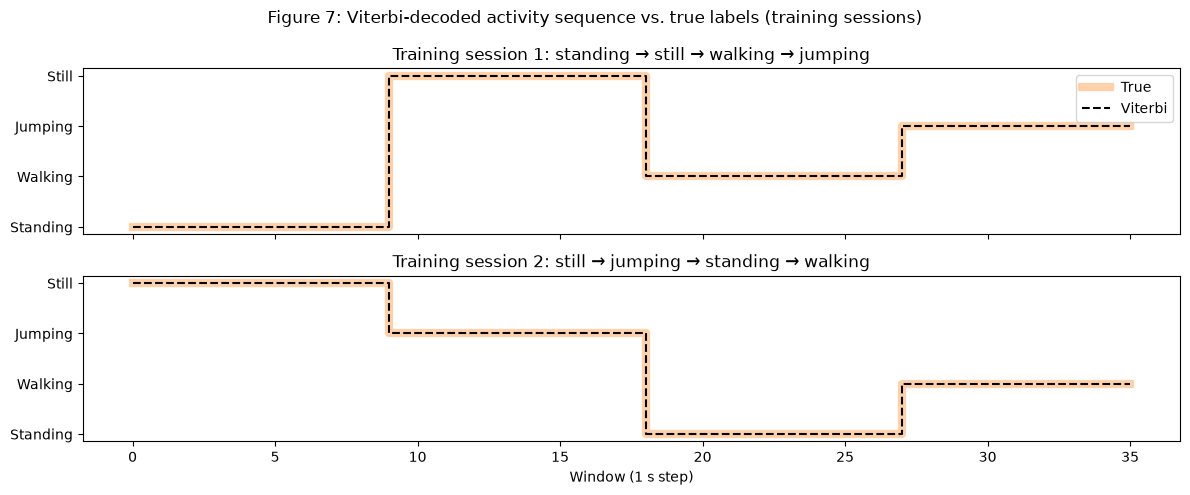

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for ax, s in zip(axes, [0, 1]):
    pred, _ = model.viterbi(train_seqs[s])
    t = np.arange(len(pred))
    ax.step(t, train_labels[s], where="post", lw=6, alpha=0.35, color="tab:orange", label="True")
    ax.step(t, pred, where="post", lw=1.5, ls="--", color="black", label="Viterbi")
    ax.set_yticks(range(model.K), labels_cap)
    ax.set_title(f"Training session {s + 1}: " + " → ".join(session_order[s]))
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Window (1 s step)")
fig.suptitle("Figure 7: Viterbi-decoded activity sequence vs. true labels (training sessions)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig7_decoded_training.png", dpi=150)
plt.show()

## 5. Evaluation on unseen data
Two new sessions (`test_01`, `test_02`, ≈65 s each) were recorded on a different occasion from the training clips. In each session the activities were performed continuously in sequence (walking → standing → jumping → still), so the test data contains real transitions, unlike the single-activity training clips. Each session was filmed, and the video was used to mark when every activity started and ended (`data/test/test_0X_labels.csv`, in seconds since Start was tapped).

Test data goes through exactly the same pipeline as training (100 Hz resampling, 2 s / 1 s windows, the same 12 features), and it is normalized with the **training** mean and standard deviation. Each window gets the label of the activity at its centre.

In [23]:
TEST_DIR = Path("data/test")

def load_test_recording(zip_path):
    """Like load_recording, but keeps the whole session (no trimming or 10 s cap) and uses
    'seconds since Start was tapped' as the time axis, so it lines up with the video-based labels."""
    with zipfile.ZipFile(zip_path) as z:
        streams = {short: pd.read_csv(z.open(f"{name}.csv")).sort_values("time").drop_duplicates("time")
                   for name, short in SENSORS.items()}
    start = max(df["seconds_elapsed"].iloc[0] for df in streams.values())
    end = min(df["seconds_elapsed"].iloc[-1] for df in streams.values())
    grid = np.ceil(start * FS) / FS + np.arange(int((end - start) * FS)) / FS
    acc = streams["acc"]
    out = pd.DataFrame({"timestamp_ns": np.interp(grid, acc["seconds_elapsed"], acc["time"]).astype("int64"),
                        "seconds": np.round(grid, 2)})
    for short, df in streams.items():
        for axis in "xyz":
            out[f"{short}_{axis}"] = np.interp(grid, df["seconds_elapsed"].to_numpy(), df[axis].to_numpy())
    return out

def label_at(times, labels_df):
    """Activity label for each time point from the video-based label file ('unlabeled' outside all intervals)."""
    out = np.full(len(times), "unlabeled", dtype=object)
    for _, row in labels_df.iterrows():
        out[(times >= row["start_s"]) & (times < row["end_s"])] = row["activity"]
    return out

test_data = {}
for zp in sorted(RAW_DIR.glob("test_*.zip")):
    name = NAME_RE.match(zp.name).group(0).lower()                      # e.g. 'test_01'
    labels_df = pd.read_csv(TEST_DIR / f"{name}_labels.csv", encoding="utf-8-sig", skipinitialspace=True)
    labels_df.columns = labels_df.columns.str.strip().str.lower()          # remove hidden spaces / BOM from headers
    labels_df["activity"] = labels_df["activity"].str.strip().str.lower()  # e.g. " Walking " -> "walking"
    labels_df[["start_s", "end_s"]] = labels_df[["start_s", "end_s"]].astype(float)    
    df = load_test_recording(zp)
    df["activity"] = label_at(df["seconds"].to_numpy(), labels_df)
    df.to_csv(TEST_DIR / f"{name}.csv", index=False)                    # clean, labelled test CSV for the dataset folder

    F = extract_features(df)
    F["activity"] = label_at(F["t_start_s"].to_numpy() + WINDOW_S / 2, labels_df)   # label at window centre
    F = F[F["activity"] != "unlabeled"].reset_index(drop=True)
    X = ((transform(F) - feat_mean) / feat_std).to_numpy()                          # TRAINING mean/std
    test_data[name] = {"X": X,
                       "y": F["activity"].map(STATE_OF).to_numpy(),
                       "t": F["t_start_s"].to_numpy() + WINDOW_S / 2}
    counts = {k: int(v) for k, v in F["activity"].value_counts().items()}
    print(f"{name}: {df['seconds'].iloc[-1]:.1f} s recorded, {len(F)} labelled windows, {counts}")

test_01: 64.3 s recorded, 62 labelled windows, {'jumping': 21, 'walking': 16, 'still': 13, 'standing': 12}
test_02: 65.9 s recorded, 64 labelled windows, {'walking': 23, 'jumping': 17, 'still': 15, 'standing': 9}


In [24]:
for name, d in test_data.items():
    d["pred"], _ = model.viterbi(d["X"])
    d["pred_indep"] = model._log_emission(d["X"]).argmax(axis=1)    # each window on its own, ignoring transitions
    print(f"{name}: Viterbi accuracy {np.mean(d['pred'] == d['y']):.3f} | "
          f"emissions only (no transitions) {np.mean(d['pred_indep'] == d['y']):.3f}")

y_true = np.concatenate([d["y"] for d in test_data.values()])
y_pred = np.concatenate([d["pred"] for d in test_data.values()])

test_01: Viterbi accuracy 0.952 | emissions only (no transitions) 0.952
test_02: Viterbi accuracy 0.938 | emissions only (no transitions) 0.938


Overall accuracy: 0.944  (119/126 windows)


,State (Activity),Number of Samples,Sensitivity,Specificity,Accuracy (TP+TN)/N
0,Standing,21,0.857,1.000,0.976
1,Walking,39,1.000,0.931,0.952
2,Jumping,38,0.947,0.989,0.976
3,Still,28,0.929,1.000,0.984


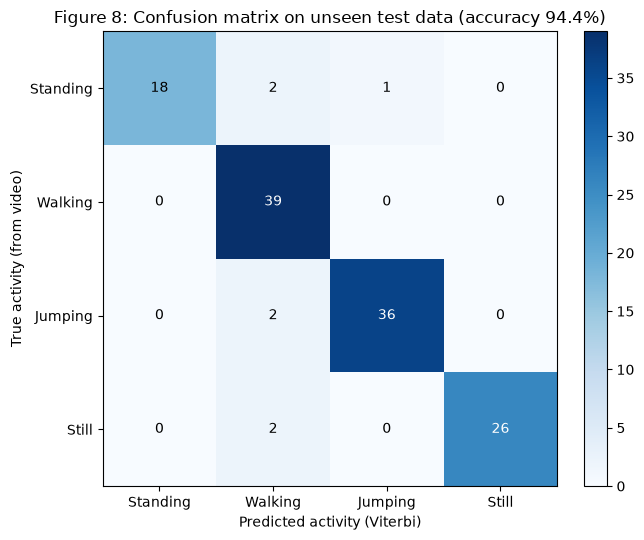

In [25]:
K = len(ACTIVITIES)
cm = np.zeros((K, K), dtype=int)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1
N = cm.sum()
overall_acc = np.trace(cm) / N

rows = []
for k, a in enumerate(ACTIVITIES):
    TP = cm[k, k]
    FN = cm[k].sum() - TP
    FP = cm[:, k].sum() - TP
    TN = N - TP - FN - FP
    rows.append({"State (Activity)": a.capitalize(),
                 "Number of Samples": int(cm[k].sum()),
                 "Sensitivity": round(TP / (TP + FN), 3) if TP + FN else np.nan,
                 "Specificity": round(TN / (TN + FP), 3) if TN + FP else np.nan,
                 "Accuracy (TP+TN)/N": round((TP + TN) / N, 3)})
results = pd.DataFrame(rows)
print(f"Overall accuracy: {overall_acc:.3f}  ({np.trace(cm)}/{N} windows)")
display(results)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm, cmap="Blues")
for i in range(K):
    for j in range(K):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(K), labels_cap)
ax.set_yticks(range(K), labels_cap)
ax.set_xlabel("Predicted activity (Viterbi)")
ax.set_ylabel("True activity (from video)")
ax.set_title(f"Figure 8: Confusion matrix on unseen test data (accuracy {overall_acc:.1%})")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig8_confusion_matrix.png", dpi=150)
plt.show()

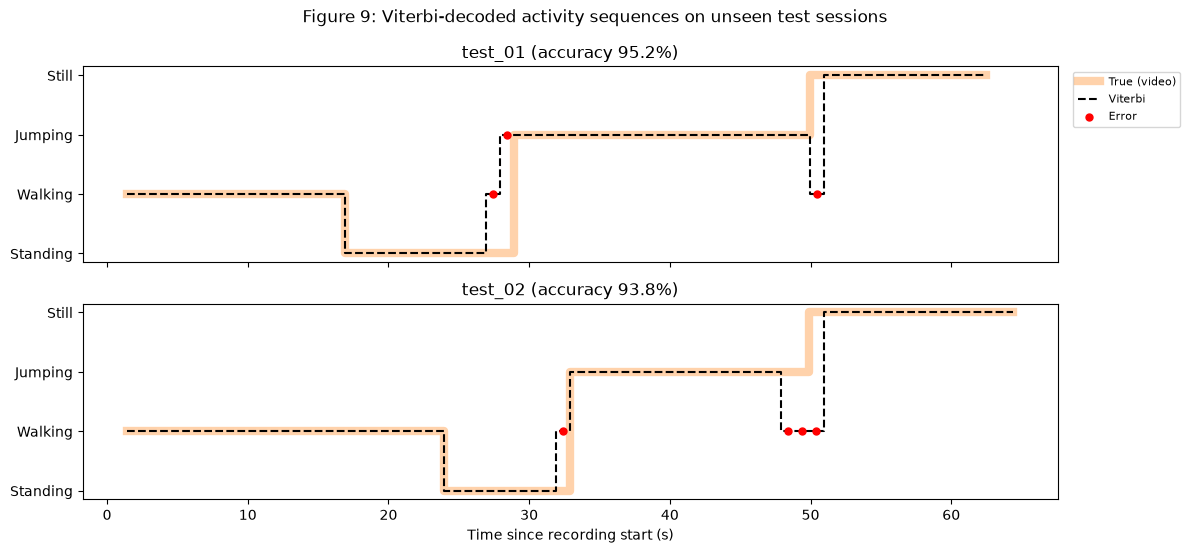

In [26]:
fig, axes = plt.subplots(len(test_data), 1, figsize=(12, 2.8 * len(test_data)), sharex=True, squeeze=False)
for ax, (name, d) in zip(axes[:, 0], test_data.items()):
    ax.step(d["t"], d["y"], where="mid", lw=6, alpha=0.35, color="tab:orange", label="True (video)")
    ax.step(d["t"], d["pred"], where="mid", lw=1.5, ls="--", color="black", label="Viterbi")
    wrong = d["pred"] != d["y"]
    ax.scatter(d["t"][wrong], d["pred"][wrong], color="red", zorder=3, s=25, label="Error")
    ax.set_yticks(range(K), labels_cap)
    ax.set_title(f"{name} (accuracy {np.mean(~wrong):.1%})")
axes[0, 0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[-1, 0].set_xlabel("Time since recording start (s)")
fig.suptitle("Figure 9: Viterbi-decoded activity sequences on unseen test sessions")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig9_decoded_test.png", dpi=150)
plt.show()

## 6. Summary

- **Data:** 52 training clips (13 per activity, 10 s each, 130 s per activity) and 2 unseen test sessions, recorded on a Huawei P20 at ≈98 Hz and resampled to 100 Hz.
- **Features:** 12 per 2 s window (8 time-domain, 4 FFT-based). Intensity features are log-transformed, then everything is Z-score normalized using training statistics only.
- **Model:** a 4-state Gaussian HMM written from scratch in NumPy. The implementation (forward-backward, Baum-Welch with ε = 1e-4, Viterbi) was verified on synthetic data: 9 iterations, monotonic log-likelihood, 97.3% decoding accuracy.
- **Result on unseen data:** **94.4% accuracy (119/126 windows)**. Every error falls within ≈2 s of an activity change, where a window mixes two activities. Walking is the easiest activity (sensitivity 1.000); standing is the hardest (0.857).
- **Key insight:** the features separate the activities so clearly that Viterbi and per-window classification give the same accuracy. The learned transition matrix reflects the recording protocol (≈11 s bouts) rather than natural behaviour; learning realistic transitions would require long, natural recordings.

The full discussion is in `report/report.pdf`.